# CBM Inference — Sliding Window over an ECG Record

This notebook loads a trained **Concept Bottleneck Model (CBM)** and runs it in a dense
sliding-window fashion over a single 10-second PTB-XL record.

For every window we get:
- **10 concept probabilities** `[P, Q, R, S, T, U, PR, QRS, ST, QT]` — how confident the model is that each wave/interval is present.
- **Concept uncertainties** (aleatoric, from the heteroscedastic concept heads).
- **Task probability** — whether the window contains a complete heartbeat (QRS present).
- **MC-Dropout uncertainty** — epistemic uncertainty over the task prediction.

In [ ]:
import sys
from pathlib import Path

# ── Load user path config (config.toml) ──────────────────────────────────
try:
    import tomllib                      # stdlib Python ≥ 3.11
except ModuleNotFoundError:
    import tomli as tomllib             # pip install tomli

with open("config.toml", "rb") as _f:
    _paths = tomllib.load(_f)["paths"]

REPO_ROOT = Path(_paths["repo_root"])
sys.path.insert(0, str(REPO_ROOT))
sys.path.insert(0, str(REPO_ROOT / "src"))

# All configurable paths — derived from config.toml
RUN_DIR   = REPO_ROOT / _paths["run_dir"]   if not Path(_paths["run_dir"]).is_absolute()   else Path(_paths["run_dir"])
DATA_PATH = Path(_paths["data_dir"]) / _paths["data_path"] if not Path(_paths["data_path"]).is_absolute() else Path(_paths["data_path"])

# ── Standard imports ──────────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import torch
import yaml
import wfdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from src.data import (
    bandpass_filter, minmax_normalize, delineate_record,
    PTBXL_ROOT, BEAT_CONCEPT_NAMES,
)
from src.models import build_model, CONCEPT_NAMES

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device    : {DEVICE}")
print(f"Repo root : {REPO_ROOT}")
print(f"Run dir   : {RUN_DIR}")
print(f"Data path : {DATA_PATH}")


Device : cuda


## 1 — Load checkpoint and config

In [ ]:
# RUN_DIR is set in the setup cell from config.toml
with open(RUN_DIR / "config.yaml") as f:
    cfg = yaml.safe_load(f)

model = build_model(cfg)
ckpt  = torch.load(RUN_DIR / "checkpoints/best_model.pt", map_location=DEVICE)
model.load_state_dict(ckpt["model"])
model = model.to(DEVICE)
model.eval()

T_FIXED       = cfg["data"]["t_fixed"]          # 500 samples = 1 s at 500 Hz
STRIDE        = cfg["data"]["stride"]            # 50 samples  = 100 ms
SAMPLING_RATE = cfg["data"]["sampling_rate"]     # 500 Hz
LEAD_IDX      = 0                               # Lead I for display
N_MC          = 100                             # MC-Dropout samples

print(f"Checkpoint epoch : {ckpt['epoch']}")
print(f"Val loss         : {ckpt['val_loss']:.4f}")
print(f"Window size      : {T_FIXED} samples ({T_FIXED/SAMPLING_RATE*1000:.0f} ms)")
print(f"Stride           : {STRIDE} samples ({STRIDE/SAMPLING_RATE*1000:.0f} ms)")


Checkpoint epoch : 20
Val loss         : 0.0025
Window size      : 500 samples (1000 ms)
Stride           : 50 samples (100 ms)


## 2 — Load and preprocess one ECG record

Record  : records500/00000/00009_hr  (ecg_id=9)
R-peaks : 10 detected


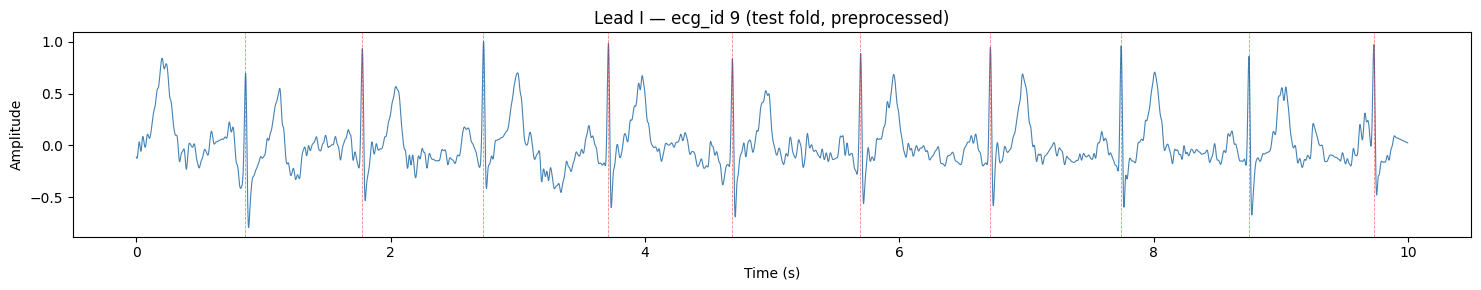

In [ ]:
# DATA_PATH is set in the setup cell from config.toml
meta = pd.read_csv(DATA_PATH / "ptbxl_database.csv", index_col="ecg_id")

# Use a test-fold record (fold 10)
test_ids = meta[meta["strat_fold"] == 10].index.tolist()

ecg_id, signal, signal_raw, header, delin = None, None, None, None, None
for cid in test_ids[:100]:
    _row = meta.loc[cid]
    _fn  = _row["filename_hr"]
    _sig, _hdr = wfdb.rdsamp(str(DATA_PATH / _fn))
    _sig = _sig.T.astype(np.float32)
    _sig_f = bandpass_filter(_sig, sampling_rate=SAMPLING_RATE)
    _sig_n = minmax_normalize(_sig_f)
    _d = delineate_record(_sig_n, sampling_rate=SAMPLING_RATE, lead_idx=LEAD_IDX)
    if _d["quality_ok"] and len(_d["r_peaks"]) >= 5:
        ecg_id, signal, signal_raw, header, delin = cid, _sig_n, _sig, _hdr, _d
        break

if ecg_id is None:
    raise RuntimeError("No suitable test record found.")

r_peaks = delin["r_peaks"]
t_axis  = np.arange(signal.shape[1]) / SAMPLING_RATE

print(f"Record  : {meta.loc[ecg_id, 'filename_hr']}  (ecg_id={ecg_id})")
print(f"R-peaks : {len(r_peaks)} detected")

fig, ax = plt.subplots(figsize=(15, 3))
ax.plot(t_axis, signal[LEAD_IDX], color="steelblue", lw=0.8)
for r in r_peaks:
    ax.axvline(t_axis[r], color="red", lw=0.6, ls="--", alpha=0.5)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title(f"Lead I — ecg_id {ecg_id} (test fold, preprocessed)")
plt.tight_layout()
plt.show()


## 3 — Sliding-window CBM inference

We pass every window through the model in one batched forward pass, then run MC-Dropout for uncertainty.

In [5]:
C, T = signal.shape
win_starts = np.arange(0, T - T_FIXED + 1, STRIDE)

# Build batch tensor: (N_windows, 12, T_FIXED)
windows = np.stack(
    [signal[:, s : s + T_FIXED] for s in win_starts], axis=0
).astype(np.float32)   # (N, 12, 500)
x_batch = torch.from_numpy(windows).to(DEVICE)   # (N, 12, 500)

# ── Deterministic forward pass ────────────────────────────────────────────
model.eval()
with torch.no_grad():
    task_probs_det, concept_probs, concept_log_vars = model(x_batch)

task_probs_det  = task_probs_det.squeeze(1).cpu().numpy()   # (N,)
concept_probs   = concept_probs.cpu().numpy()               # (N, 10)
concept_vars    = np.exp(concept_log_vars.cpu().numpy())    # (N, 10)  — aleatoric

# ── MC-Dropout uncertainty ────────────────────────────────────────────────
model.train()   # activate dropout
mc_preds = []
with torch.no_grad():
    for _ in range(N_MC):
        tp, _, _ = model(x_batch)
        mc_preds.append(tp.squeeze(1).cpu().numpy())
model.eval()

mc_preds = np.stack(mc_preds, axis=0)           # (N_MC, N)
task_mean  = mc_preds.mean(axis=0)              # (N,)
task_epistemic = mc_preds.std(axis=0)           # (N,)

print(f"Windows processed : {len(win_starts)}")
print(f"Mean task prob    : {task_mean.mean():.3f}")
print(f"Fraction > 0.5    : {(task_mean > 0.5).mean():.1%}")

Windows processed : 91
Mean task prob    : 0.639
Fraction > 0.5    : 63.7%


## 4 — Task prediction timeline

The top panel shows the ECG with predicted task probability overlaid.  
The bottom panel shows the MC-Dropout uncertainty (epistemic std) alongside the task probability.

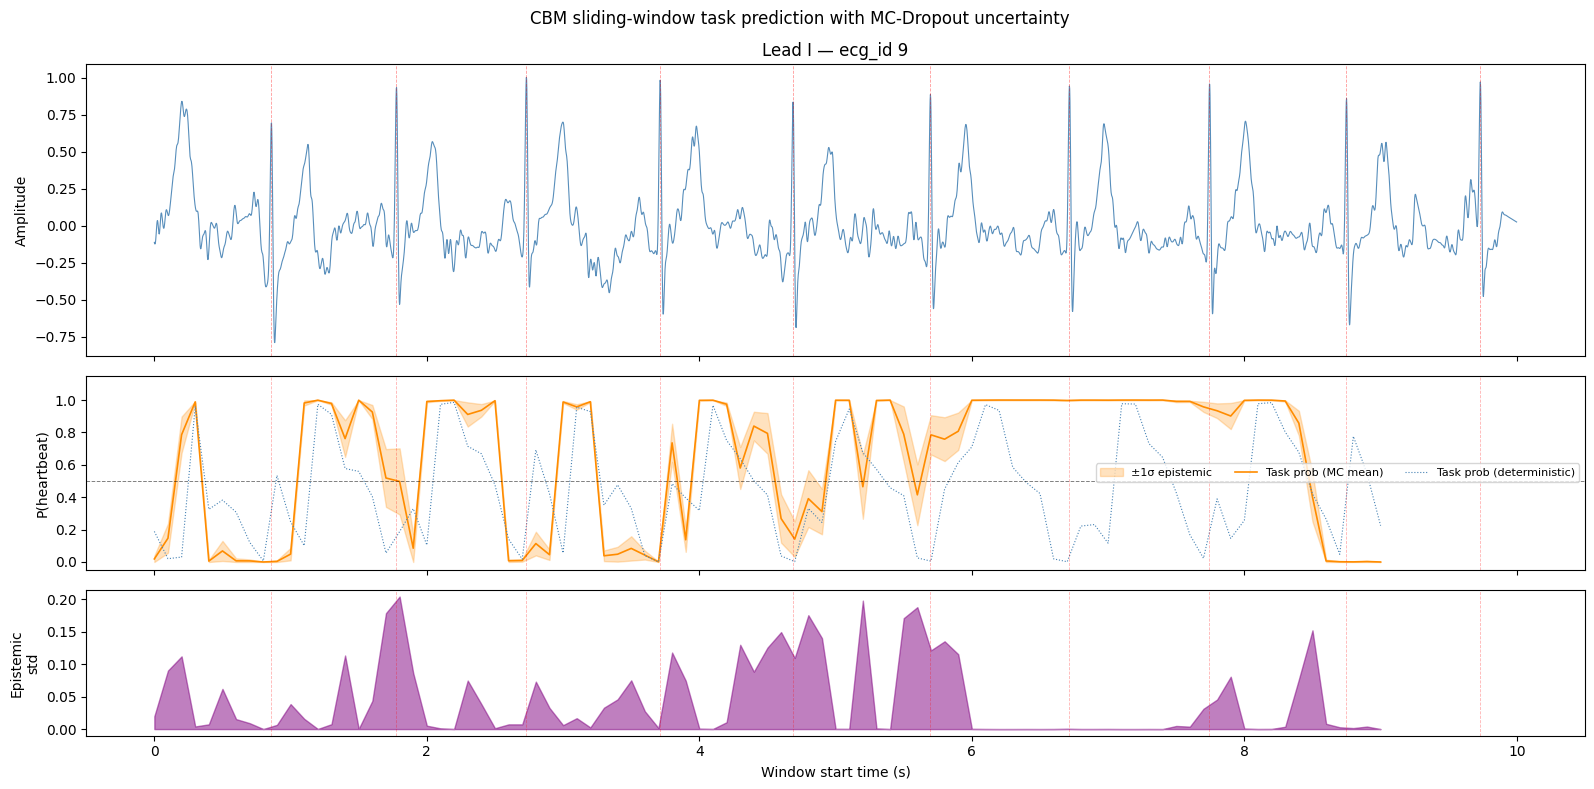

In [6]:
t_wins = t_axis[win_starts]   # window start times in seconds

fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True,
                         gridspec_kw={"height_ratios": [3, 2, 1.5]})

# ── ECG signal with task-probability colouring ────────────────────────────
axes[0].plot(t_axis, signal[LEAD_IDX], color="steelblue", lw=0.8, alpha=0.9)
for r in r_peaks:
    axes[0].axvline(t_axis[r], color="red", lw=0.6, ls="--", alpha=0.4)
axes[0].set_ylabel("Amplitude")
axes[0].set_title(f"Lead I — ecg_id {ecg_id}")

# ── Task probability + uncertainty band ───────────────────────────────────
axes[1].fill_between(t_wins,
                     np.clip(task_mean - task_epistemic, 0, 1),
                     np.clip(task_mean + task_epistemic, 0, 1),
                     alpha=0.25, color="darkorange", label="±1σ epistemic")
axes[1].plot(t_wins, task_mean, color="darkorange", lw=1.2, label="Task prob (MC mean)")
axes[1].plot(t_wins, task_probs_det, color="steelblue", lw=0.8, ls=":", label="Task prob (deterministic)")
axes[1].axhline(0.5, color="black", ls="--", lw=0.7, alpha=0.5)
for r in r_peaks:
    axes[1].axvline(t_axis[r], color="red", lw=0.6, ls="--", alpha=0.3)
axes[1].set_ylim(-0.05, 1.15)
axes[1].set_ylabel("P(heartbeat)")
axes[1].legend(fontsize=8, ncol=3)

# ── Epistemic uncertainty ─────────────────────────────────────────────────
axes[2].fill_between(t_wins, 0, task_epistemic, alpha=0.5, color="purple")
axes[2].set_ylabel("Epistemic\nstd")
axes[2].set_xlabel("Window start time (s)")
for r in r_peaks:
    axes[2].axvline(t_axis[r], color="red", lw=0.6, ls="--", alpha=0.3)

plt.suptitle("CBM sliding-window task prediction with MC-Dropout uncertainty", fontsize=12)
plt.tight_layout()
plt.show()

## 5 — Concept probability timelines

Each row shows how the model's confidence in one concept evolves as the window slides.
The shaded band is the aleatoric (heteroscedastic) uncertainty from the concept head.

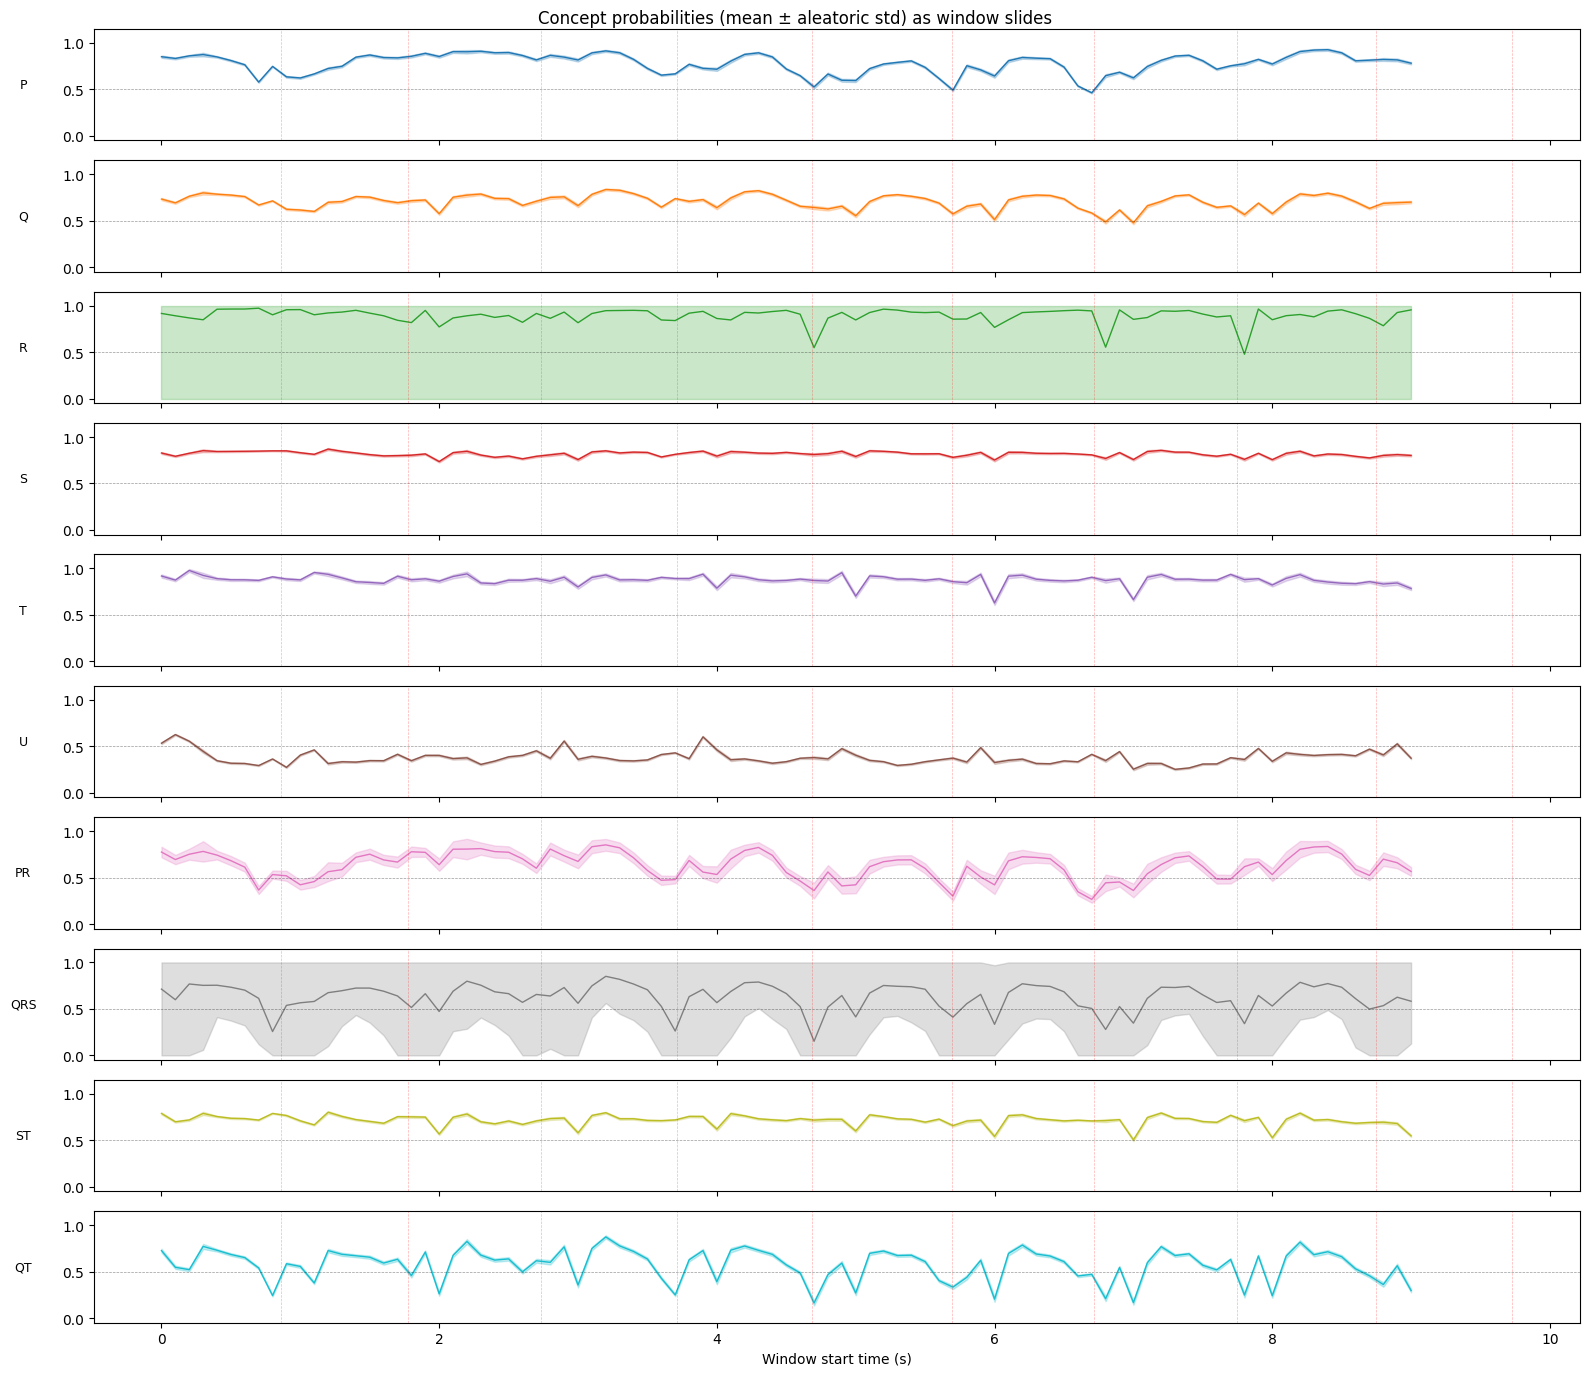

In [7]:
K = len(CONCEPT_NAMES)
colors = plt.cm.tab10(np.linspace(0, 1, K))

fig, axes = plt.subplots(K, 1, figsize=(16, 14), sharex=True)

for j, (name, color) in enumerate(zip(CONCEPT_NAMES, colors)):
    cp   = concept_probs[:, j]
    cstd = np.sqrt(concept_vars[:, j])

    axes[j].fill_between(t_wins,
                         np.clip(cp - cstd, 0, 1),
                         np.clip(cp + cstd, 0, 1),
                         alpha=0.25, color=color)
    axes[j].plot(t_wins, cp, color=color, lw=1)
    axes[j].axhline(0.5, color="black", ls="--", lw=0.5, alpha=0.4)
    axes[j].set_ylim(-0.05, 1.15)
    axes[j].set_ylabel(name, rotation=0, labelpad=28, fontsize=9, va="center")

    for r in r_peaks:
        axes[j].axvline(t_axis[r], color="red", lw=0.5, ls="--", alpha=0.3)

axes[-1].set_xlabel("Window start time (s)")
plt.suptitle("Concept probabilities (mean ± aleatoric std) as window slides", fontsize=12)
plt.tight_layout()
plt.show()

## 6 — Zoom: one beat at high temporal resolution

Zoom in on a single beat and watch how each concept fires and fades as the window sweeps through.

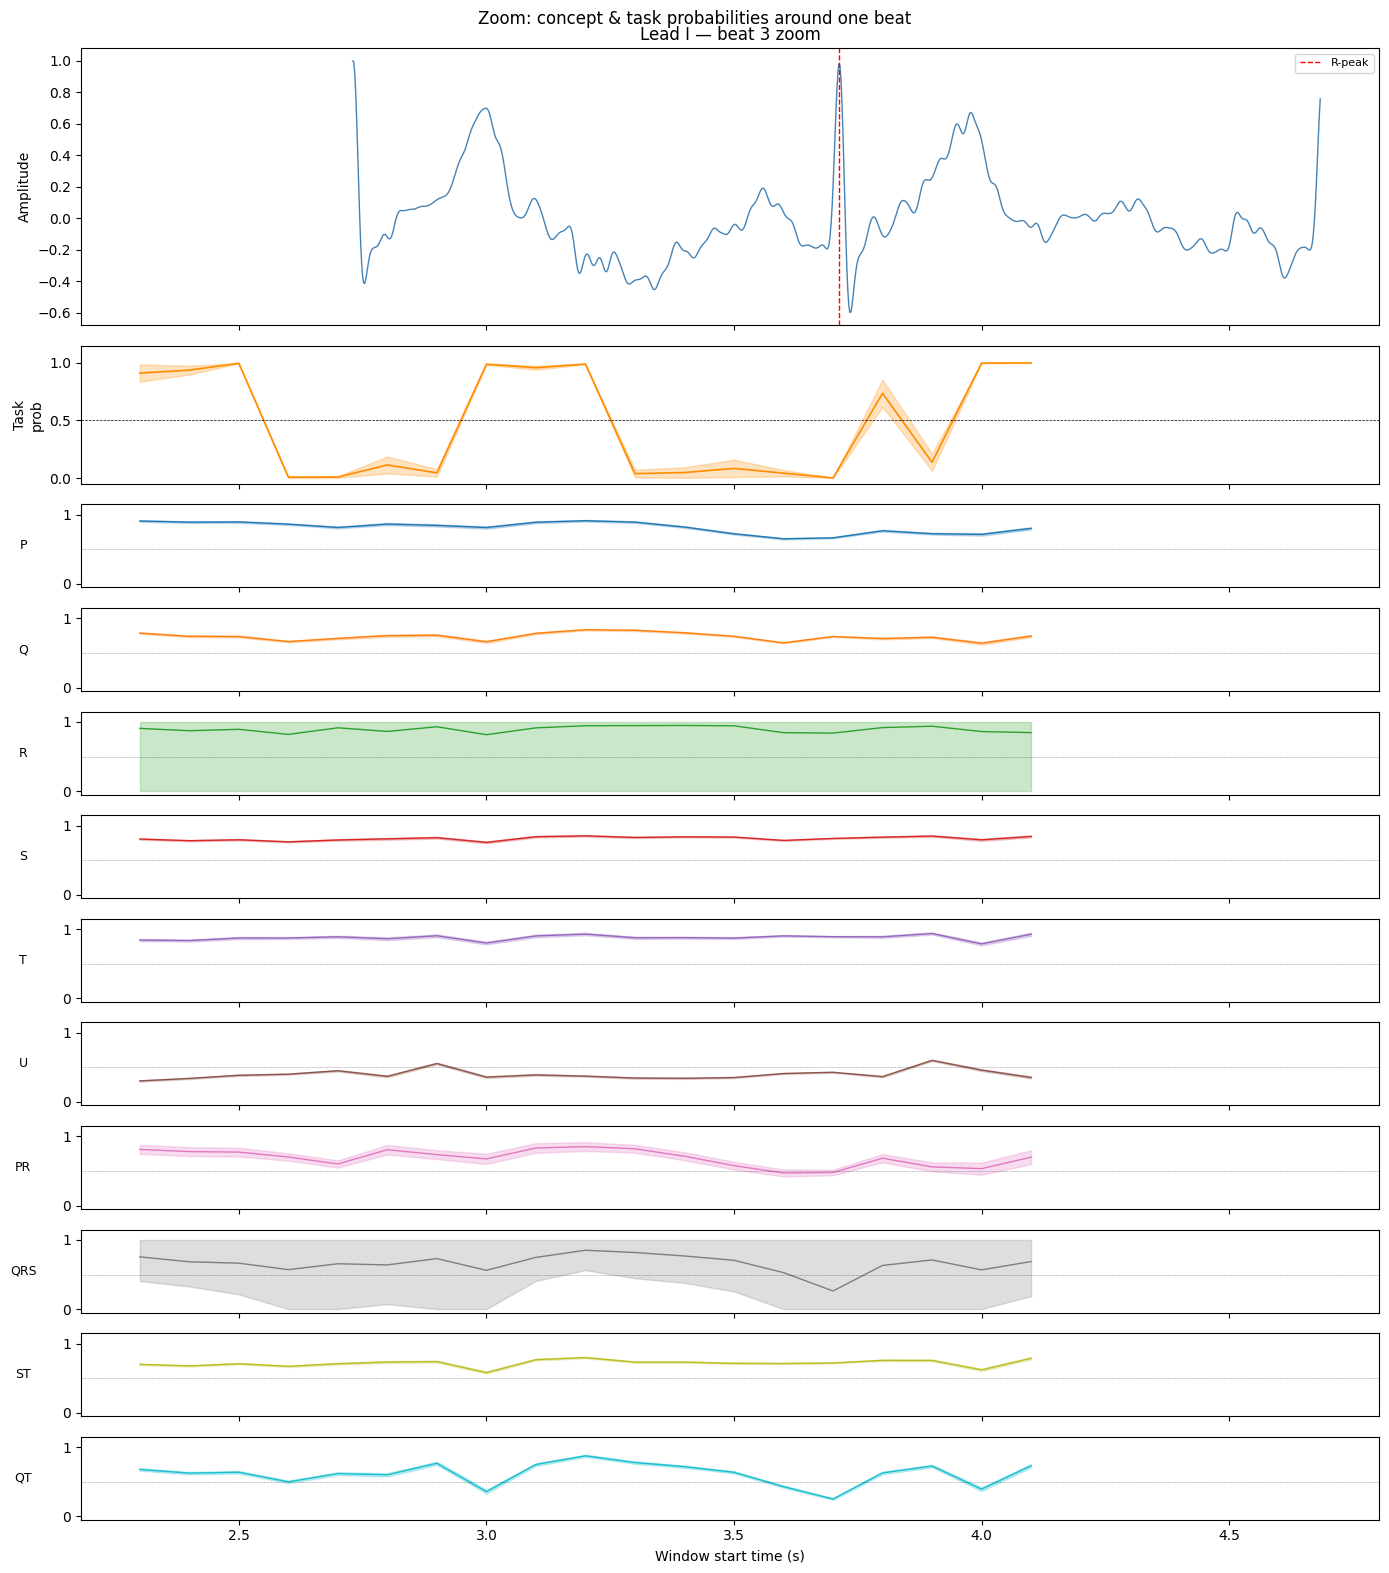

In [8]:
# Pick the 3rd R-peak as the centre of the zoom
beat_idx  = min(3, len(r_peaks) - 2)
zoom_lo   = int(r_peaks[beat_idx - 1]) if beat_idx > 0 else 0
zoom_hi   = int(r_peaks[beat_idx + 1]) if beat_idx + 1 < len(r_peaks) else T

# Windows whose centre falls in the zoom region
centres   = win_starts + T_FIXED // 2
zoom_mask = (centres >= zoom_lo) & (centres <= zoom_hi)

t_z   = t_wins[zoom_mask]
cp_z  = concept_probs[zoom_mask]   # (M, 10)
cv_z  = concept_vars[zoom_mask]    # (M, 10)
tp_z  = task_mean[zoom_mask]
te_z  = task_epistemic[zoom_mask]

fig, axes = plt.subplots(K + 2, 1, figsize=(14, 16), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1.5] + [0.9] * K})

# ECG
axes[0].plot(t_axis[zoom_lo:zoom_hi], signal[LEAD_IDX, zoom_lo:zoom_hi],
             color="steelblue", lw=1)
axes[0].axvline(t_axis[int(r_peaks[beat_idx])], color="red", lw=1, ls="--", label="R-peak")
axes[0].set_ylabel("Amplitude")
axes[0].set_title(f"Lead I — beat {beat_idx} zoom")
axes[0].legend(fontsize=8)

# Task probability
axes[1].fill_between(t_z,
                     np.clip(tp_z - te_z, 0, 1),
                     np.clip(tp_z + te_z, 0, 1),
                     alpha=0.25, color="darkorange")
axes[1].plot(t_z, tp_z, color="darkorange", lw=1.2)
axes[1].axhline(0.5, color="black", ls="--", lw=0.5)
axes[1].set_ylim(-0.05, 1.15)
axes[1].set_ylabel("Task\nprob")

# Concepts
for j, (name, color) in enumerate(zip(CONCEPT_NAMES, colors)):
    cp = cp_z[:, j]
    cv = np.sqrt(cv_z[:, j])
    axes[j + 2].fill_between(t_z, np.clip(cp - cv, 0, 1), np.clip(cp + cv, 0, 1),
                              alpha=0.25, color=color)
    axes[j + 2].plot(t_z, cp, color=color, lw=1)
    axes[j + 2].axhline(0.5, color="black", ls="--", lw=0.4, alpha=0.4)
    axes[j + 2].set_ylim(-0.05, 1.15)
    axes[j + 2].set_ylabel(name, rotation=0, labelpad=28, fontsize=9, va="center")

axes[-1].set_xlabel("Window start time (s)")
plt.suptitle("Zoom: concept & task probabilities around one beat", fontsize=12)
plt.tight_layout()
plt.show()

## 7 — Classifier weights: which concepts drive the task prediction?

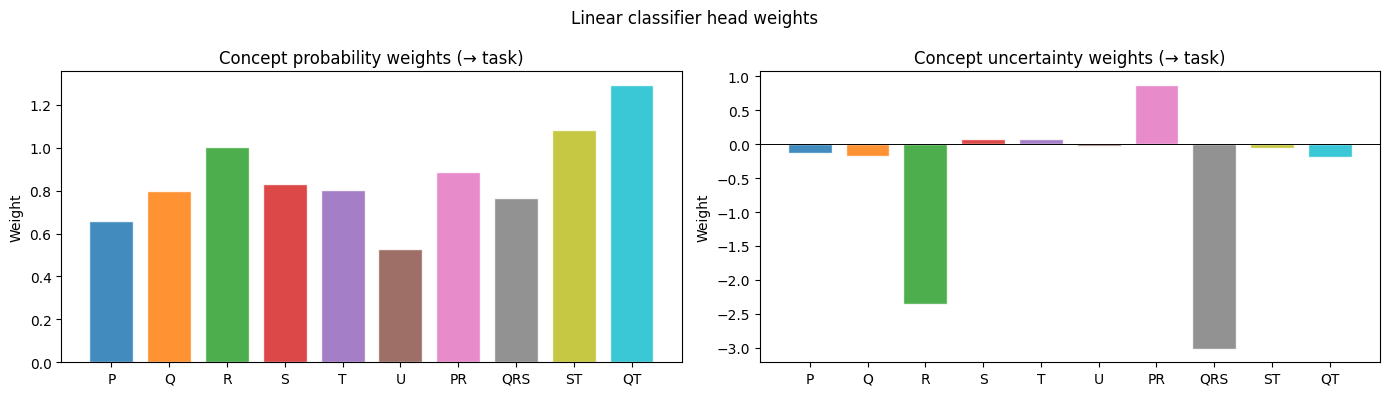


Concept probability weights:
     P  +0.659  ██████
     Q  +0.798  ███████
     R  +1.004  ██████████
     S  +0.829  ████████
     T  +0.803  ████████
     U  +0.526  █████
    PR  +0.888  ████████
   QRS  +0.765  ███████
    ST  +1.081  ██████████
    QT  +1.291  ████████████


In [9]:
weights = model.classifier.get_weights_dict(CONCEPT_NAMES)

prob_w   = [weights[n]["prob_weight"]   for n in CONCEPT_NAMES]
uncert_w = [weights[n]["uncert_weight"] for n in CONCEPT_NAMES]

x_pos = np.arange(len(CONCEPT_NAMES))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

bars = axes[0].bar(x_pos, prob_w, width=width * 2, color=colors, edgecolor="white", alpha=0.85)
axes[0].axhline(0, color="black", lw=0.7)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(CONCEPT_NAMES)
axes[0].set_ylabel("Weight")
axes[0].set_title("Concept probability weights (→ task)")

axes[1].bar(x_pos, uncert_w, width=width * 2, color=colors, edgecolor="white", alpha=0.85)
axes[1].axhline(0, color="black", lw=0.7)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(CONCEPT_NAMES)
axes[1].set_ylabel("Weight")
axes[1].set_title("Concept uncertainty weights (→ task)")

plt.suptitle("Linear classifier head weights", fontsize=12)
plt.tight_layout()
plt.show()

print("\nConcept probability weights:")
for name, w in zip(CONCEPT_NAMES, prob_w):
    bar = "█" * int(abs(w) * 10) if abs(w) * 10 >= 1 else "·"
    print(f"  {name:>4s}  {w:+.3f}  {bar}")

## 8 — Concept × task correlation heatmap

Pearson correlation between each concept probability and the task prediction across all sliding windows.

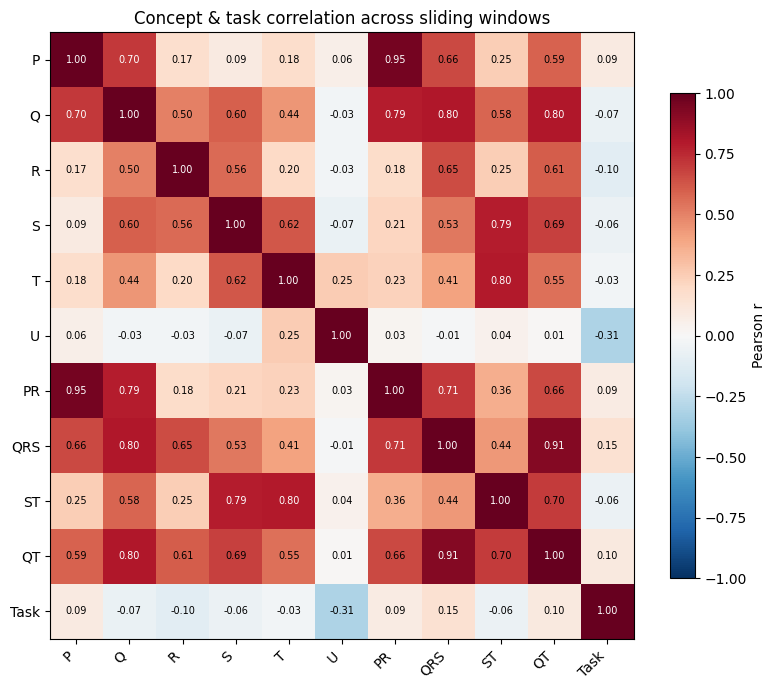

In [10]:
import numpy as np

# Correlation matrix: (10 concepts + task) × (10 concepts + task)
all_signals = np.hstack([concept_probs, task_mean[:, None]])   # (N, 11)
labels_all  = CONCEPT_NAMES + ["Task"]
corr = np.corrcoef(all_signals.T)   # (11, 11)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
plt.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_xticks(range(len(labels_all)))
ax.set_yticks(range(len(labels_all)))
ax.set_xticklabels(labels_all, rotation=45, ha="right")
ax.set_yticklabels(labels_all)

for i in range(len(labels_all)):
    for j in range(len(labels_all)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center",
                fontsize=7, color="black" if abs(corr[i, j]) < 0.7 else "white")

ax.set_title("Concept & task correlation across sliding windows")
plt.tight_layout()
plt.show()

## 9 — Challenging samples

We select three categories of records that are harder for the model:

| Category | Why challenging |
|---|---|
| **Atrial fibrillation (AFIB)** | Absent P waves, irregularly irregular rhythm |
| **Bundle branch block (LBBB/RBBB)** | Abnormal, wide QRS morphology |
| **Premature ventricular complex (PVC)** | Ectopic beats with very different morphology |

For each category we find the first qualifying test-fold record, run the full
sliding-window inference, and display the ECG + task probability side by side.


In [12]:
import ast

def parse_scp(scp_str):
    try:
        return ast.literal_eval(scp_str)
    except Exception:
        return {}

def run_inference(sig):
    """Deterministic + MC-Dropout inference on a full 12-lead signal (12, T)."""
    ws = np.arange(0, sig.shape[1] - T_FIXED + 1, STRIDE)
    wins = np.stack([sig[:, s:s + T_FIXED] for s in ws], axis=0).astype(np.float32)
    xb = torch.from_numpy(wins).to(DEVICE)

    model.eval()
    with torch.no_grad():
        tp_det, cp_, clv_ = model(xb)
    tp_det = tp_det.squeeze(1).cpu().numpy()
    cp_    = cp_.cpu().numpy()
    clv_   = np.exp(clv_.cpu().numpy())

    model.train()
    mc_ = []
    with torch.no_grad():
        for _ in range(N_MC):
            tp_, _, _ = model(xb)
            mc_.append(tp_.squeeze(1).cpu().numpy())
    model.eval()
    mc_ = np.stack(mc_, axis=0)
    return ws, tp_det, cp_, clv_, mc_.mean(0), mc_.std(0)

def find_record(keyword_set, fold=10, max_search=300):
    """Find first test-fold record whose SCP codes intersect keyword_set."""
    for cid in meta[meta['strat_fold'] == fold].index[:max_search]:
        scps = set(parse_scp(meta.loc[cid, 'scp_codes']).keys())
        if not scps.isdisjoint(keyword_set):
            fn = meta.loc[cid, 'filename_hr']
            sig_raw, _ = wfdb.rdsamp(str(DATA_PATH / fn))
            sig_n = minmax_normalize(bandpass_filter(sig_raw.T.astype(np.float32),
                                                     sampling_rate=SAMPLING_RATE))
            d = delineate_record(sig_n, sampling_rate=SAMPLING_RATE, lead_idx=LEAD_IDX)
            if d['quality_ok']:
                return cid, sig_n, d, meta.loc[cid, 'scp_codes']
    return None, None, None, None

challenges = [
    ('AFIB', {'AFIB'},                'Atrial fibrillation (AFIB)'),
    ('BBB',  {'CLBBB', 'CRBBB', 'ILBBB', 'IRBBB'}, 'Bundle branch block (LBBB/RBBB)'),
    ('PVC',  {'PVC',  'PAC', 'SVPB'}, 'Premature beat (PVC/PAC)'),
]

records = {}
for key, keywords, label in challenges:
    cid, sig, d, scps = find_record(keywords)
    if cid is not None:
        records[key] = dict(label=label, ecg_id=cid, signal=sig,
                            r_peaks=d['r_peaks'], scps=scps)
        print(f"{label:40s}  ecg_id={cid}  r-peaks={len(d['r_peaks'])}  codes={str(scps)[:80]}")
    else:
        print(f'[!] No record found for {key}')


Atrial fibrillation (AFIB)                ecg_id=581  r-peaks=7  codes={'ASMI': 100.0, 'IVCD': 100.0, 'NST_': 0.0, 'AFIB': 0.0}
Bundle branch block (LBBB/RBBB)           ecg_id=65  r-peaks=12  codes={'IRBBB': 100.0, 'SR': 0.0}
Premature beat (PVC/PAC)                  ecg_id=427  r-peaks=13  codes={'NDT': 100.0, 'PAC': 0.0, 'SR': 0.0}


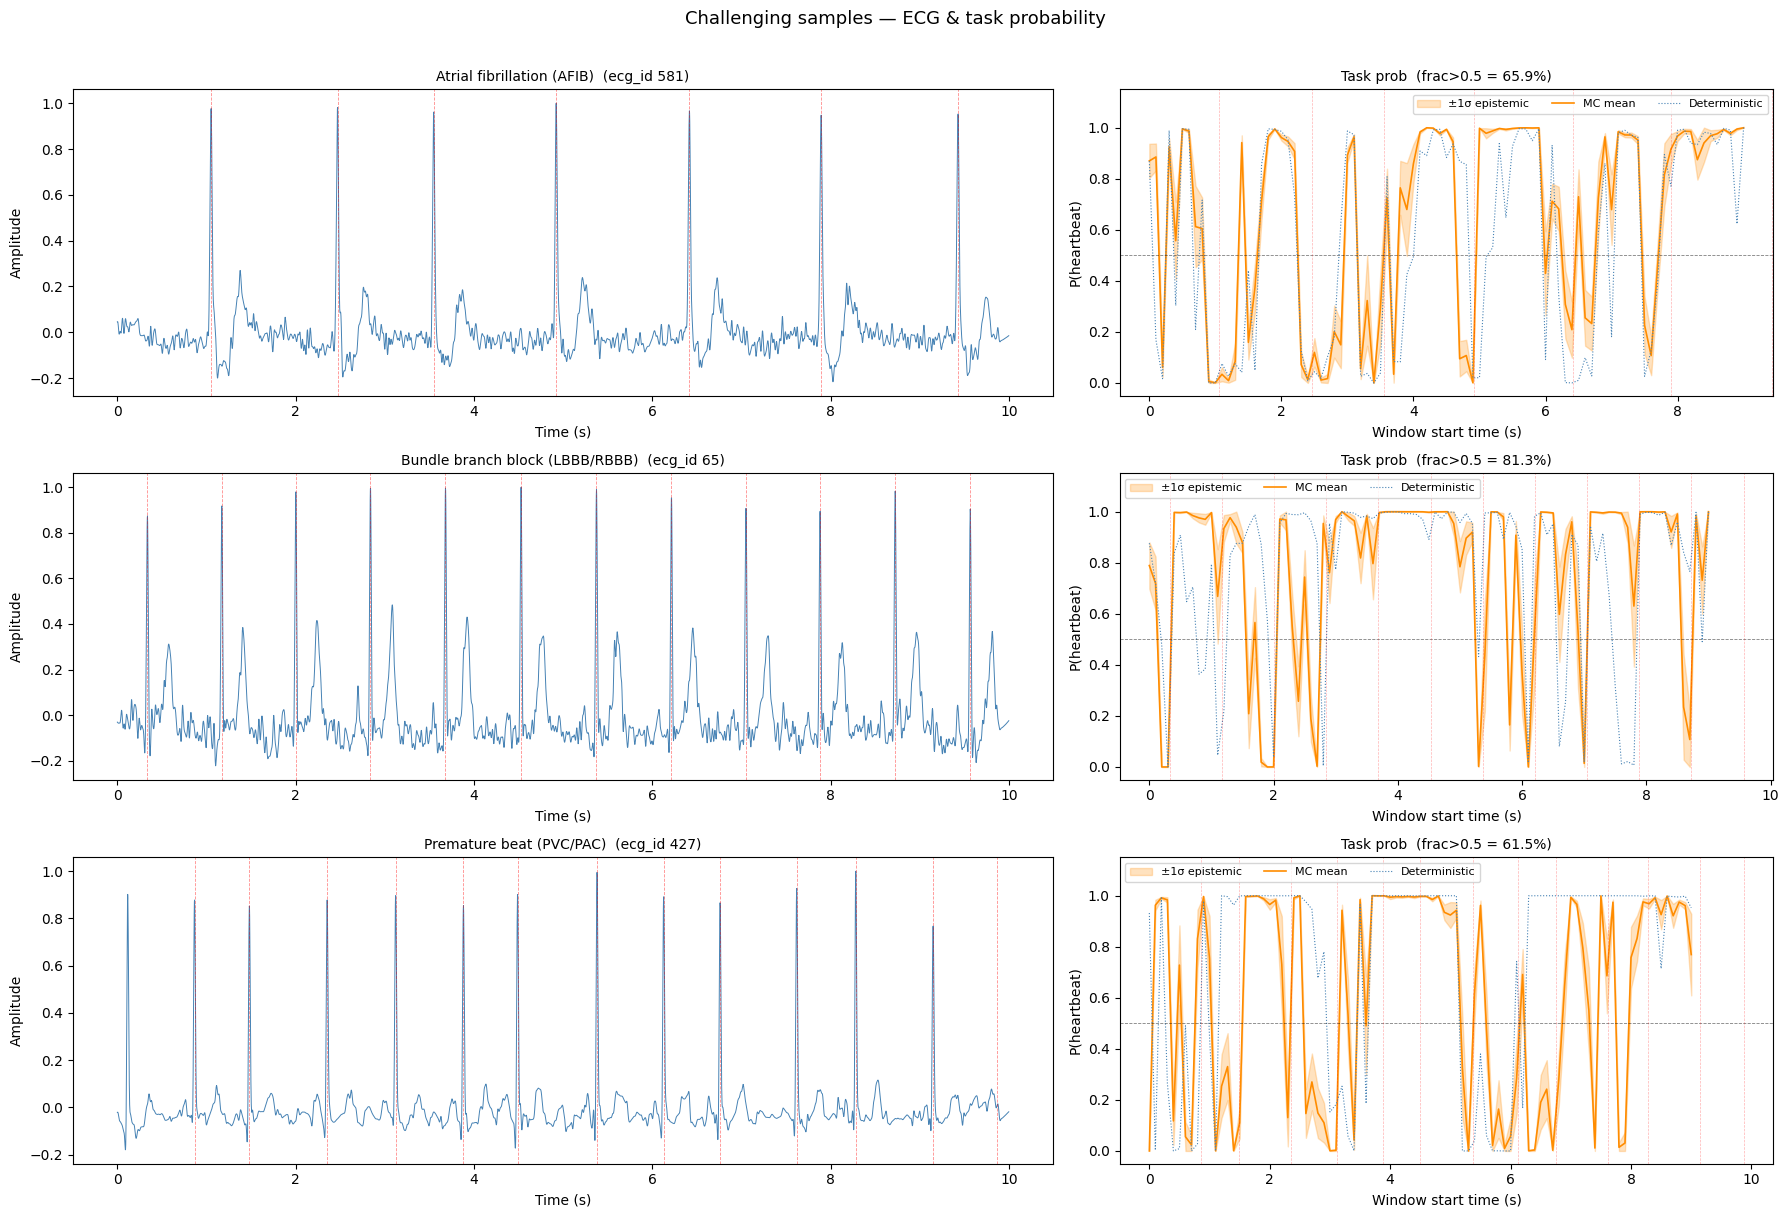

In [13]:
# ── ECG + task probability for each challenging record ────────────────────
fig, axes = plt.subplots(len(records), 2, figsize=(18, 4 * len(records)),
                         gridspec_kw={'width_ratios': [3, 2]})
if len(records) == 1:
    axes = axes[np.newaxis, :]

for row_idx, (key, rec) in enumerate(records.items()):
    sig, rp = rec['signal'], rec['r_peaks']
    t_ax    = np.arange(sig.shape[1]) / SAMPLING_RATE

    ws, tp_det, cp_, clv_, t_mean, t_ep = run_inference(sig)
    t_w = t_ax[ws]

    ax_ecg = axes[row_idx, 0]
    ax_ecg.plot(t_ax, sig[LEAD_IDX], color='steelblue', lw=0.7)
    for r in rp:
        ax_ecg.axvline(t_ax[int(r)], color='red', lw=0.6, ls='--', alpha=0.45)
    ax_ecg.set_title(f"{rec['label']}  (ecg_id {rec['ecg_id']})", fontsize=10)
    ax_ecg.set_xlabel('Time (s)')
    ax_ecg.set_ylabel('Amplitude')

    ax_tp = axes[row_idx, 1]
    ax_tp.fill_between(t_w, np.clip(t_mean - t_ep, 0, 1), np.clip(t_mean + t_ep, 0, 1),
                       alpha=0.25, color='darkorange', label='\u00b11\u03c3 epistemic')
    ax_tp.plot(t_w, t_mean,  color='darkorange', lw=1.2, label='MC mean')
    ax_tp.plot(t_w, tp_det,  color='steelblue',  lw=0.8, ls=':', label='Deterministic')
    ax_tp.axhline(0.5, color='black', ls='--', lw=0.6, alpha=0.5)
    for r in rp:
        ax_tp.axvline(t_ax[int(r)], color='red', lw=0.5, ls='--', alpha=0.3)
    ax_tp.set_ylim(-0.05, 1.15)
    ax_tp.set_xlabel('Window start time (s)')
    ax_tp.set_ylabel('P(heartbeat)')
    ax_tp.legend(fontsize=8, ncol=3)
    ax_tp.set_title(f"Task prob  (frac>0.5 = {(t_mean > 0.5).mean():.1%})", fontsize=10)

plt.suptitle('Challenging samples \u2014 ECG & task probability', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


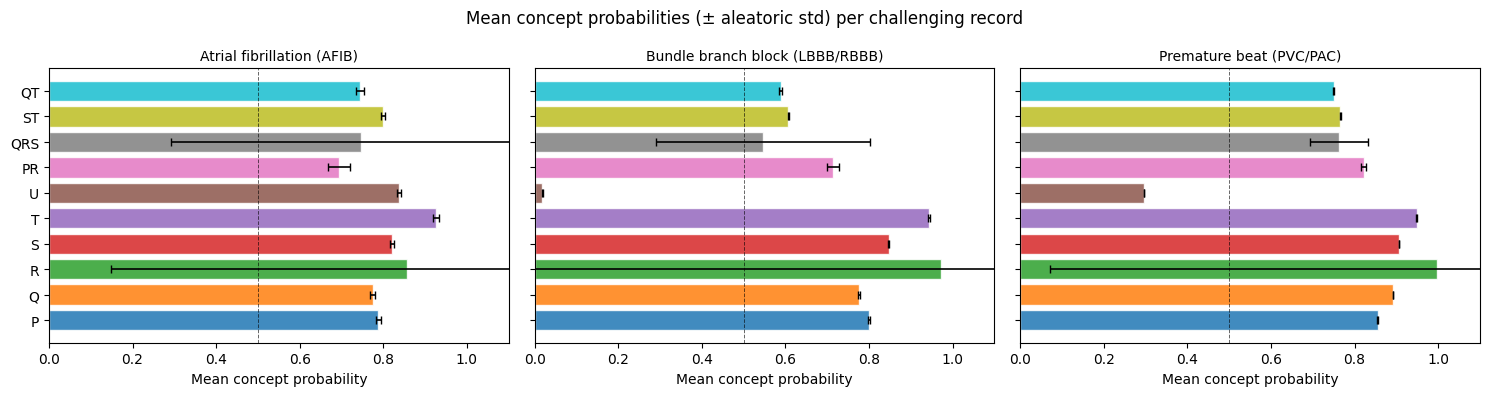

In [14]:
# ── Mean concept probabilities per challenging record ─────────────────────
colors_c = plt.cm.tab10(np.linspace(0, 1, len(CONCEPT_NAMES)))

fig, axes = plt.subplots(1, len(records), figsize=(5 * len(records), 4), sharey=True)
if len(records) == 1:
    axes = [axes]

for ax_h, (key, rec) in zip(axes, records.items()):
    _, _, cp_, clv_, _, _ = run_inference(rec['signal'])
    mean_cp = cp_.mean(axis=0)
    std_cp  = np.sqrt(clv_).mean(axis=0)

    ax_h.barh(CONCEPT_NAMES, mean_cp, xerr=std_cp,
              color=colors_c, edgecolor='white', alpha=0.85,
              error_kw={'elinewidth': 1.2, 'capsize': 3})
    ax_h.axvline(0.5, color='black', ls='--', lw=0.7, alpha=0.6)
    ax_h.set_xlim(0, 1.1)
    ax_h.set_xlabel('Mean concept probability')
    ax_h.set_title(rec['label'], fontsize=10)

plt.suptitle('Mean concept probabilities (\u00b1 aleatoric std) per challenging record',
             fontsize=12)
plt.tight_layout()
plt.show()
